In [18]:
import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
from skimage import measure
import os
import pandas as pd
import scipy.io as sio
import logging

logging.getLogger().setLevel(logging.ERROR)
basepath =  r"W:\data\PPP\PPP20\day5"
basename=os.path.basename(basepath)# Define the new folder path
#create working folder
new_folder_path = os.path.join(basepath, "complex_system")
brain_region="CA1"
animal="mouse"   #or Mouse
cell_type='all'
path_parts = basepath.split("\\")  # Split the path using backslash
animal_name = path_parts[-2]  # Second-to-last part is the animal name
day = path_parts[-1]  # Last part is the day
save_dir = r"D:\Documents\GitHub\R_Project\PPP\codebook\Criticality_analysis\complex_system\manifold"
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
# Create the folder if it doesn't exist
if not os.path.exists(new_folder_path):
    os.makedirs(new_folder_path)
    print(f"Folder created: {new_folder_path}")
else:
    print(f"Folder already exists: {new_folder_path}")
# load in spike data from hpc pyramidal cells
st, cm = loading.load_spikes(
    basepath, brainRegion=brain_region                          # putativeCellType="Pyr"
)
# load theta epochs
state_dict = loading.load_SleepState_states(basepath)
nrem_epochs = nel.EpochArray(
    state_dict["NREMstate"],
)
awake_epochs = nel.EpochArray(
    state_dict["WAKEstate"],
)
# theta_epochs = nel.EpochArray(
#     state_dict["THETA"],
# )
rem_epochs=nel.EpochArray(state_dict["REMstate"],)
try:
    # Try default loader
    epoch_df = loading.load_epoch(basepath)
except Exception as e:
    print(f"load_epoch failed with error: {e}")
    print("Falling back to manual .mat file load...")

    # Load the .mat file
    mat = sio.loadmat(os.path.join(basepath, "DayNight25.MergePoints.events.mat"), squeeze_me=True)

    # Extract the 'MergePoints' structure
    merge_points = mat['MergePoints']

    # Extract the timestamps array: shape (N, 2)
    timestamps = merge_points['timestamps']
    # Unwrap the array inside
    timestamps = np.array(timestamps.tolist())

    # shape (N, 2)
    epoch_df = pd.DataFrame(timestamps, columns=["startTime", "stopTime"])

sleep_epochs = nel.EpochArray(np.array([epoch_df.startTime, epoch_df.stopTime]).T)
E_spikes = st.time[(cm.putativeCellType == 'Pyramidal Cell')]
I_spikes= st.time[(cm.putativeCellType.str.contains("Interneuron"))]
spike_times=st.time
n_cell=len(spike_times)
print(f"number of cells: {n_cell}")

Folder already exists: W:\data\PPP\PPP20\day5\complex_system
number of cells: 297


In [19]:
epoch_df

,name,startTime,stopTime,environment,manipulation,behavioralParadigm,stimuli,notes,basepath
0,preSleep_240117_090247,0.0000,7425.90715,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
1,freeT1_240117_111103,7425.9072,9380.74875,T_maze,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
2,midSleep_240117_114727,9380.7488,17050.11195,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
3,freeT2_240117_135922,17050.1120,18726.80315,T_maze,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
4,postSleep_240117_143136,18726.8032,29235.59035,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5


In [20]:
import os, re, numpy as np, pandas as pd
import glob
def _load_mat_any(mat_path):
    from scipy.io import loadmat
    try:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False,
            simplify_cells=True
        )
    except TypeError:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False
        )
    except NotImplementedError:
        import mat73
        return mat73.loadmat(mat_path)
def _to_1d_array(x):
    """
    Coerce a MATLAB-loaded field to a 1D numpy array.
    - Scalars -> 1-length array
    - Lists/tuples/ndarrays -> flattened 1D
    - None / missing -> empty array
    """
    if x is None:
        return np.array([], dtype=float)
    arr = np.asarray(x, dtype=object)  # start as object to avoid surprises
    if arr.ndim == 0:
        # scalar or unsized object
        return np.atleast_1d(arr).astype(float, copy=False)
    # flatten and try float cast (ignore non-numeric gracefully)
    try:
        return np.asarray(arr).ravel().astype(float, copy=False)
    except (ValueError, TypeError):
        # fallback: best-effort, convert elementwise
        return np.array([float(v) for v in np.ravel(arr)], dtype=float)

def _to_state_str(s):
    # MATLAB char arrays sometimes come in as numpy arrays
    try:
        if isinstance(s, (bytes, bytearray)):
            return s.decode('utf-8', 'ignore')
        if isinstance(s, str):
            return s
        # arrays or weird containers -> join characters
        arr = np.asarray(s)
        if arr.ndim == 0:
            return str(arr.item())
        # e.g., array of characters
        return ''.join(arr.tolist()) if arr.dtype.kind in ('U','S') else str(arr)
    except Exception:
        return str(s)

def load_d2_timeline_complete(basepath, region):
    """Loads all sleep-state data, including d2_err."""
    region = region.upper()
    search_dir = os.path.join(basepath, "complex_system")
    # pats = [f"*_{region}_D2_time_resolved_rippleablate.mat", f"*_{region}_D2_time_rippleablate.mat"]
    pats = [f"*_{region}_D2_time_resolved_error_bar_forplot.mat", f"*_{region}_D2_time_error_bar_forplot.mat"]
    files = []
    for pat in pats:
        files.extend(glob.glob(os.path.join(search_dir, pat)))
    if not files:
        raise FileNotFoundError(f"No *_{region}_D2_time*.mat under {search_dir}")

    mat_path = max(files, key=os.path.getmtime)
    print(f"Loading: {os.path.basename(mat_path)}")

    mat = _load_mat_any(mat_path)
    results = mat['results']
    params = mat.get('params', {})

    # Make results iterable no matter if it's a list, ndarray, or dict
    if isinstance(results, dict):
        iter_results = list(results.values())
    else:
        iter_results = list(results if isinstance(results, (list, tuple)) else np.atleast_1d(results))

    print(f"📊 Found {len(iter_results)} result items (sleep states)")
    print(f"📊 Parameters: {params}")

    # Try to infer animal/day from filename if available
    fname = os.path.basename(mat_path)
    animal_name = None
    day = None
    m_day = re.search(r'day(\d+)', fname, flags=re.I)
    if m_day:
        day = int(m_day.group(1))
    m_animal = re.match(r'([^_]+)_day\d+_', fname)
    if m_animal:
        animal_name = m_animal.group(1)

    all_centers, all_d2, all_d2err, all_states = [], [], [], []
    n_states_with_err = 0

    for i, result_item in enumerate(iter_results):
        # Access as dict-like regardless of MATLAB struct quirks
        state = _to_state_str(result_item.get('state', 'UNKNOWN')) if hasattr(result_item, 'get') else \
                _to_state_str(result_item['state']) if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) else 'UNKNOWN'

        centers_raw = result_item.get('center', []) if hasattr(result_item, 'get') else \
                      (result_item['center'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'center' in result_item else [])
        d2_raw = result_item.get('d2', []) if hasattr(result_item, 'get') else \
                 (result_item['d2'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2' in result_item else [])
        d2err_raw = result_item.get('d2_err', []) if hasattr(result_item, 'get') else \
                    (result_item['d2_err'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2_err' in result_item else [])

        centers  = _to_1d_array(centers_raw)
        d2_vals  = _to_1d_array(d2_raw)
        d2_err   = _to_1d_array(d2err_raw)

        # Presence flag (some states may not have d2_err)
        has_err = d2_err.size > 0 and np.any(np.isfinite(d2_err))
        n_states_with_err += int(has_err)

        # Harmonize lengths: truncate all to the common min
        sizes = [centers.size, d2_vals.size] + ([d2_err.size] if has_err else [])
        n_pts = min(sizes) if min(sizes) > 0 else 0
        print(f"   State {i}: {state} - requested points={centers.size}, actual used={n_pts}")

        if n_pts == 0:
            print("     ⚠️ Empty state - no data points")
            continue

        centers = centers[:n_pts]
        d2_vals = d2_vals[:n_pts]
        d2_err  = (d2_err[:n_pts] if has_err else np.full(n_pts, np.nan, dtype=float))

        # Ranges
        try:
            print(f"     Time range: {float(np.nanmin(centers))} to {float(np.nanmax(centers))}")
        except ValueError:
            print("     Time range: (all NaN)")

        try:
            print(f"     D2 range: {float(np.nanmin(d2_vals)):.4f} to {float(np.nanmax(d2_vals)):.4f}")
        except ValueError:
            print("     D2 range: (all NaN)")

        if np.any(np.isfinite(d2_err)):
            try:
                dmin, dmax = float(np.nanmin(d2_err)), float(np.nanmax(d2_err))
                print(f"     D2_ERR range: {dmin:.4f} to {dmax:.4f}")
            except ValueError:
                print("     D2_ERR range: (all NaN)")
        else:
            print("     D2_ERR: missing → filled with NaN")

        all_centers.append(centers)
        all_d2.append(d2_vals)
        all_d2err.append(d2_err)
        all_states.append(np.array([state]*n_pts, dtype=object))

    if len(all_centers) == 0:
        raise ValueError("No data found in any sleep state - all states are empty")

    # Concatenate
    all_centers = np.concatenate(all_centers)
    all_d2      = np.concatenate(all_d2)
    all_d2err   = np.concatenate(all_d2err)
    all_states  = np.concatenate(all_states)

    # DataFrame (include d2_err)
    df = pd.DataFrame({
        'center_s': all_centers.astype(float, copy=False),
        'd2':       all_d2.astype(float, copy=False),
        'd2_err':   all_d2err.astype(float, copy=False),
        'state':    all_states.astype(str)
    }).sort_values('center_s').reset_index(drop=True)

    print(f"\n✅ Complete timeline created:")
    print(f"📊 Total data points: {len(df)}")
    print(f"📊 Time range: {df['center_s'].min()} to {df['center_s'].max()}")
    print(f"📊 Duration: {(df['center_s'].max() - df['center_s'].min()):.1f} seconds")
    print(f"📊 State distribution:")
    print(df['state'].value_counts())

    # Empty-state tracker
    empty_states = []
    for ri in iter_results:
        st = _to_state_str(ri.get('state','UNKNOWN')) if hasattr(ri,'get') else \
             _to_state_str(ri['state']) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'state' in ri else 'UNKNOWN'
        csz = np.size(np.atleast_1d(ri.get('center', []))) if hasattr(ri,'get') else \
              np.size(np.atleast_1d(ri['center'])) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'center' in ri else 0
        if csz == 0:
            empty_states.append(st)

    meta = {
        "animal_name": animal_name,
        "day": day,
        "region": region,
        "path": mat_path,
        "params": params,
        "columns": list(df.columns),
        "shape": df.shape,
        "n_states": len(iter_results),
        "states_with_d2_err": n_states_with_err,
        "empty_states": empty_states
    }

    return df, meta



try:
    ca1_complete_df, ca1_complete_meta = load_d2_timeline_complete(basepath, "CA1")
    
    # pfc_complete_df, pfc_complete_meta = load_d2_timeline_complete(basepath, "PFC")

    
except Exception as e:
    print(f"❌ Failed: {e}")
    import traceback
    traceback.print_exc()

print("\n" + "="*60)

Loading: day5_CA1_D2_time_resolved_error_bar_forplot.mat
📊 Found 3 result items (sleep states)
📊 Parameters: {'window_size': 30, 'step_size': 2, 'guard_sec': 5, 'deltaT': 0.04, 'order': 20, 'quant': 0.1, 'brain_region': 'CA1', 'n_cells': 297, 'total_spikes': 14473408}
   State 0: NREM - requested points=5872, actual used=5872
     Time range: 897.0 to 29144.0
     D2 range: 0.0245 to 0.1913
     D2_ERR range: 0.0087 to 0.0304
   State 1: REM - requested points=276, actual used=276
     Time range: 3106.0 to 27958.0
     D2 range: 0.0198 to 0.0953
     D2_ERR range: 0.0074 to 0.0171
   State 2: WAKE - requested points=4718, actual used=4718
     Time range: 21.0 to 28954.0
     D2 range: 0.0127 to 0.2294
     D2_ERR range: 0.0058 to 0.0332

✅ Complete timeline created:
📊 Total data points: 10866
📊 Time range: 21.0 to 29144.0
📊 Duration: 29123.0 seconds
📊 State distribution:
state
NREM    5872
WAKE    4718
REM      276
Name: count, dtype: int64



In [21]:
ca1_complete_df

,center_s,d2,d2_err,state
0,21.0,0.035498,0.010854,WAKE
1,23.0,0.036828,0.010988,WAKE
2,25.0,0.027892,0.009803,WAKE
3,27.0,0.030062,0.010027,WAKE
4,29.0,0.030993,0.010261,WAKE
...,...,...,...,...
10861,29136.0,0.060522,0.012323,NREM
10862,29138.0,0.062283,0.012105,NREM
10863,29140.0,0.050122,0.011190,NREM
10864,29142.0,0.050907,0.011140,NREM


In [22]:
epoch_df

,name,startTime,stopTime,environment,manipulation,behavioralParadigm,stimuli,notes,basepath
0,preSleep_240117_090247,0.0000,7425.90715,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
1,freeT1_240117_111103,7425.9072,9380.74875,T_maze,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
2,midSleep_240117_114727,9380.7488,17050.11195,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
3,freeT2_240117_135922,17050.1120,18726.80315,T_maze,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
4,postSleep_240117_143136,18726.8032,29235.59035,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5


In [23]:
import numpy as np
from scipy.signal import welch
import nelpy as nel

def _flatten_spike_times(spike_times):
    """Accepts list/tuple/array of arrays or a single 1D array, returns sorted 1D float array."""
    if isinstance(spike_times, (list, tuple)):
        # list of arrays or scalars
        if len(spike_times) == 0:
            return np.array([], dtype=float)
        if hasattr(spike_times[0], "__len__") and not np.isscalar(spike_times[0]):
            times = np.concatenate([np.asarray(st, dtype=float).ravel()
                                    for st in spike_times if st is not None and len(st) > 0])
        else:
            times = np.asarray(spike_times, dtype=float).ravel()
    else:
        arr = np.asarray(spike_times, dtype=object)
        if arr.dtype == object:
            times = np.concatenate([np.asarray(st, dtype=float).ravel()
                                    for st in arr if st is not None and len(st) > 0])
        else:
            times = arr.astype(float).ravel()

    times = times[np.isfinite(times)]
    if times.size == 0:
        raise ValueError("No valid spike times found after flattening.")
    return np.sort(times)

def bin_spikes(spike_times, bin_size=0.04, t_start=None, t_stop=None):
    st = _flatten_spike_times(spike_times)
    if t_start is None: t_start = float(np.floor(st.min()))
    if t_stop  is None: t_stop  = float(np.ceil(st.max()))
    edges = np.arange(t_start, t_stop + bin_size, bin_size)
    counts, _ = np.histogram(st, bins=edges)
    rates = counts / bin_size
    t = edges[:-1] + bin_size/2
    return t, rates

# def segments_from_epochs(t, x, epochs):
#     arr = epochs.data if isinstance(epochs, nel.EpochArray) else np.asarray(epochs)
#     return [x[(t >= s) & (t < e)] for s, e in arr if np.any((t >= s) & (t < e))]

In [24]:
# Create plot for random 200 second segment containing all states
import matplotlib.pyplot as plt
import numpy as np
import random

# First compute MUA from spike times
print("Computing MUA firing rate from spike times...")
print("="*50)

# Compute MUA firing rate with 0.04 second bins
time_bins, firing_rate = bin_spikes(spike_times, bin_size=0.04)

Computing MUA firing rate from spike times...


In [25]:
import numpy as np
import pandas as pd

# --- Inputs assumed to exist ---
# time_bins, firing_rate  # from bin_spikes(..., bin_size=0.04)
# ca1_complete_df          # has a 'center_s' column

# 1) Make sure we have bin *centers* that match firing_rate length
tb = np.asarray(time_bins, float).ravel()
fr = np.asarray(firing_rate, float).ravel()

if tb.size == fr.size + 1:            # looks like edges → make centers
    t = 0.5 * (tb[:-1] + tb[1:])
elif tb.size == fr.size:               # already centers
    t = tb
else:
    raise ValueError("time_bins length must equal firing_rate length or be exactly one longer (edges).")

# 2) Clean + sort
ok = np.isfinite(t) & np.isfinite(fr)
t, fr = t[ok], fr[ok]
ordr = np.argsort(t)
t, fr = t[ordr], fr[ordr]

# 3) 30 s centered moving average of MUA (Hz)
dt = float(np.median(np.diff(t)))
win_s = 30.0
win_n = max(int(round(win_s / dt)), 1)

# Use pandas rolling for a centered window; allow some tolerance near edges
fr_series = pd.Series(fr, index=pd.Index(t, name="t"))
fr_30s = fr_series.rolling(window=win_n, center=True, min_periods=max(1, win_n//4)).mean().to_numpy()

# 4) Interpolate the smoothed MUA onto the D² centers
centers = np.asarray(ca1_complete_df["center_s"], float)
mua_at_centers = np.interp(centers, t, fr_30s, left=np.nan, right=np.nan)

# 5) Save to dataframe (Hz)
ca1_complete_df["MUA"] = mua_at_centers


SWR and barrage

In [26]:
import numpy as np
import scipy.io as sio      
import scipy
# Load ripple events
ripple_events = loading.load_ripples_events(basepath=basepath)
ripple_epochs = nel.EpochArray(np.array([ripple_events.start, ripple_events.stop]).T)
ripple_peaks=ripple_events.peaks
    # Load barrage events
ripple_epochs=nrem_epochs&ripple_epochs
try:
    # Load barrage events
    #brpath=r"W:\data\PPP\CA2\PPP7\day8"
    barrage_events = loading.load_barrage_events(basepath=basepath)  
    # Create barrage epochs
    barrage_epochs = nel.EpochArray(np.array([barrage_events.start, barrage_events.stop]).T)
    # Find barrages in NREM epochs
    barrages_in_nrem = barrage_epochs & nrem_epochs
    mat_path = os.path.join(basepath, f'{basename}.HSEn2.events.mat')

    data = scipy.io.loadmat(mat_path, struct_as_record=False, squeeze_me=True)
    barrage = data['HSEn2']
    barrage_timestamps= barrage.timestamps 
    barrage_epochs=nrem_epochs&barrage_epochs
except Exception as e:
    # General exception for unexpected errors
    print(f"No barrage file: {e}")
    barrage_epochs=[]
    # Extract start times

No barrage file: 'DataFrame' object has no attribute 'start'


D:\Documents\GitHub\neuro_py\neuro_py\io\loading.py:1036: UserWarning: No barrage file found for W:\data\PPP\PPP20\day5


Plot example PPP20 day5

In [27]:
import numpy as np
import nelpy as nel

# ---------- interval helpers ----------
def _merge_intervals(iv, tol=0.0):
    iv = np.asarray(iv, float)
    if iv.size == 0:
        return np.empty((0, 2), float)
    iv = iv[np.isfinite(iv).all(axis=1)]
    iv = iv[iv[:, 1] > iv[:, 0]]
    if iv.size == 0:
        return np.empty((0, 2), float)

    iv = iv[np.argsort(iv[:, 0])]
    out = [iv[0].copy()]
    for s, e in iv[1:]:
        if s <= out[-1][1] + tol:
            out[-1][1] = max(out[-1][1], e)
        else:
            out.append([s, e])
    return np.asarray(out, float)

def _subtract_intervals(iv, cut):
    iv = _merge_intervals(iv)
    cut = _merge_intervals(cut)
    if iv.size == 0 or cut.size == 0:
        return iv

    res = []
    j = 0
    for s, e in iv:
        cur_s, cur_e = s, e
        while j < len(cut) and cut[j, 1] <= cur_s:
            j += 1
        k = j
        while k < len(cut) and cut[k, 0] < cur_e:
            cs, ce = cut[k]
            if cs > cur_s:
                res.append([cur_s, min(cs, cur_e)])
            cur_s = max(cur_s, ce)
            if cur_s >= cur_e:
                break
            k += 1
        if cur_s < cur_e:
            res.append([cur_s, cur_e])
    return _merge_intervals(np.asarray(res, float))

def _union_intervals(a, b):
    a = np.asarray(a, float); b = np.asarray(b, float)
    if a.size == 0: return _merge_intervals(b)
    if b.size == 0: return _merge_intervals(a)
    return _merge_intervals(np.vstack([a, b]))

def _gap_overlaps_any(gap_s, gap_e, other):
    """other must be merged & sorted."""
    other = np.asarray(other, float)
    if other.size == 0:
        return False
    # find first interval that could overlap: start < gap_e
    i = np.searchsorted(other[:, 0], gap_e, side="left")
    # candidates are i-1 and i
    for j in (i-1, i):
        if 0 <= j < len(other):
            s, e = other[j]
            if (s < gap_e) and (e > gap_s):
                return True
    return False

def _merge_with_bridge_no_conflict(iv, other_union, bridge_gap_sec=0.0):
    """
    Merge consecutive intervals in iv if the gap <= bridge_gap_sec AND
    the gap is not overlapped by other_union (other states).
    """
    iv = _merge_intervals(iv, tol=0.0)
    other_union = _merge_intervals(other_union, tol=0.0)
    if iv.size == 0:
        return iv
    out = [iv[0].copy()]
    for s, e in iv[1:]:
        gap_s = out[-1][1]
        gap_e = s
        gap = gap_e - gap_s
        if gap <= bridge_gap_sec and gap > 0:
            # only bridge if no other state occupies the gap
            if not _gap_overlaps_any(gap_s, gap_e, other_union):
                out[-1][1] = max(out[-1][1], e)
            else:
                out.append([s, e])
        elif gap <= 0:
            # overlapping/touching -> merge
            out[-1][1] = max(out[-1][1], e)
        else:
            out.append([s, e])
    return np.asarray(out, float)

# ---------- main cleaning ----------
def clean_and_reassign_epochs(nrem_epochs, awake_epochs, rem_epochs,
                              corrections,
                              bridge_gap_sec=0.0):
    """
    corrections: list of (start, stop, target_state) target_state in {"NREM","WAKE","REM"}
    bridge_gap_sec: merge same-state epochs across small gaps IF the gap has no other state.
    Returns new nel.EpochArray objects.
    """
    nrem_iv  = np.asarray(nrem_epochs.data, float)
    awake_iv = np.asarray(awake_epochs.data, float)
    rem_iv   = np.asarray(rem_epochs.data, float)

    # 1) apply corrections: remove from all, add to target
    for (t0, t1, target) in corrections:
        cut = np.array([[float(t0), float(t1)]], float)

        nrem_iv  = _subtract_intervals(nrem_iv,  cut)
        awake_iv = _subtract_intervals(awake_iv, cut)
        rem_iv   = _subtract_intervals(rem_iv,   cut)

        target = target.upper()
        if target == "NREM":
            nrem_iv = _union_intervals(nrem_iv, cut)
        elif target == "WAKE":
            awake_iv = _union_intervals(awake_iv, cut)
        elif target == "REM":
            rem_iv = _union_intervals(rem_iv, cut)
        else:
            raise ValueError(f"Unknown target state: {target}")

    # 2) base merge (strict)
    nrem_iv  = _merge_intervals(nrem_iv,  tol=0.0)
    awake_iv = _merge_intervals(awake_iv, tol=0.0)
    rem_iv   = _merge_intervals(rem_iv,   tol=0.0)

    # 3) optional: bridge small gaps within the same state (no-conflict)
    if bridge_gap_sec and bridge_gap_sec > 0:
        # do 2 passes to reduce order-dependence
        for _ in range(2):
            nrem_iv  = _merge_with_bridge_no_conflict(nrem_iv,  _union_intervals(awake_iv, rem_iv), bridge_gap_sec)
            awake_iv = _merge_with_bridge_no_conflict(awake_iv, _union_intervals(nrem_iv,  rem_iv), bridge_gap_sec)
            rem_iv   = _merge_with_bridge_no_conflict(rem_iv,   _union_intervals(nrem_iv,  awake_iv), bridge_gap_sec)

    return nel.EpochArray(nrem_iv), nel.EpochArray(awake_iv), nel.EpochArray(rem_iv)

# ---------- usage ----------
corrections = [
    (5288.0, 5295.0, "NREM"),
    (5806.0, 5814.0, "WAKE"),
    (6039.0, 6063.0, "WAKE"),
    (6077.0, 6107.0, "WAKE"),
    (9756.0, 9769.0, "WAKE"),
]

# Example: bridge gaps up to 2 seconds if no other state occupies them
nrem_epochs, awake_epochs, rem_epochs = clean_and_reassign_epochs(
    nrem_epochs, awake_epochs, rem_epochs,
    corrections,
    bridge_gap_sec=2.0
)

print("Updated counts:")
print("NREM:",  nrem_epochs.data.shape[0])
print("WAKE:",  awake_epochs.data.shape[0])
print("REM:",   rem_epochs.data.shape[0])


Updated counts:
NREM: 131
WAKE: 134
REM: 12


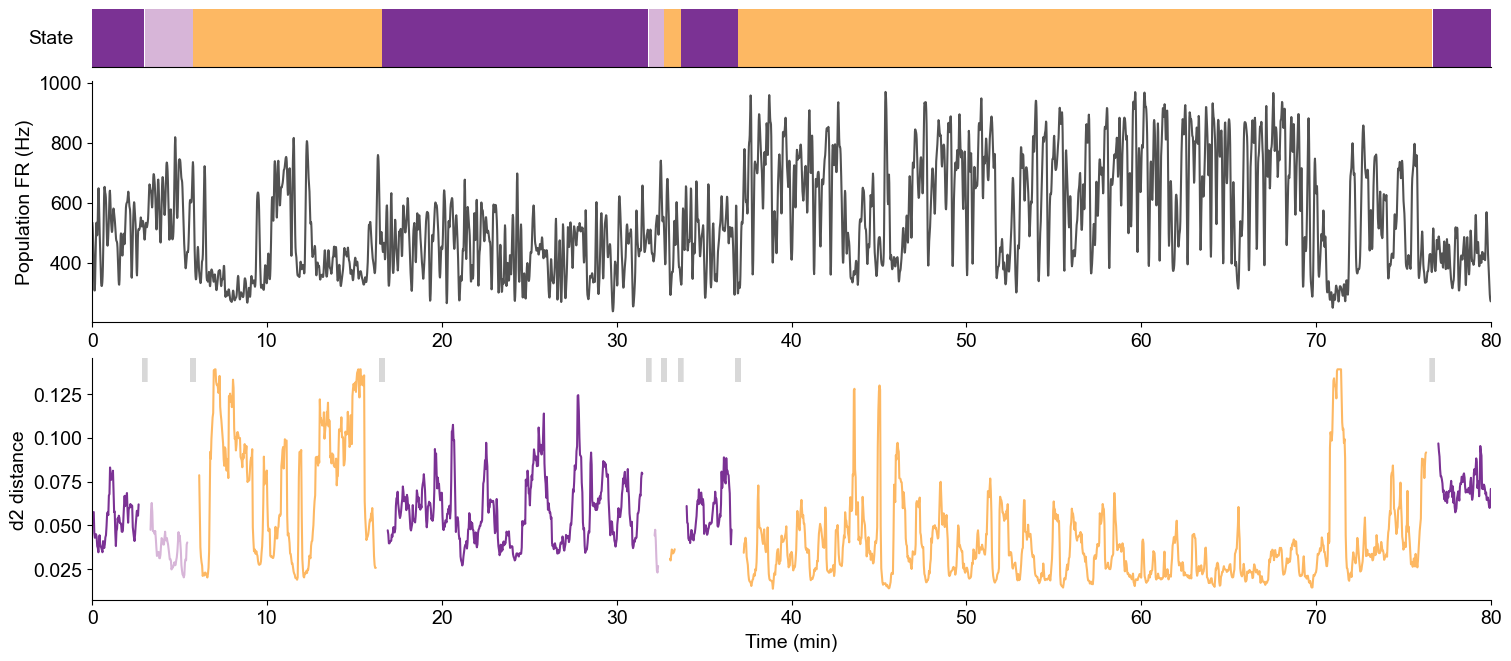

In [28]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import butter, filtfilt
from matplotlib.ticker import MultipleLocator, FuncFormatter
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import butter, filtfilt
from matplotlib.ticker import MultipleLocator, FuncFormatter
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import butter, filtfilt
import matplotlib as mpl

import matplotlib as mpl

# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
def plot_mua_with_states_topbar(
    time_bins, firing_rate, nrem_epochs, awake_epochs, rem_epochs,
    *,
    bin_size=0.04,
    cap_pct=99.5, short_sec=0.5, long_sec=5.0,
    ds_sec=1.0, use_butter=False,
    start_time=5915.5, end_time=8915.5,
    # --- third subplot (D² timeline) ---
    d2_df=None,                # DataFrame with columns: center_s, d2 (and optional state)
    d2_cap_pct=99.5,
    d2_smooth_sec=0,
    d2_scatter_alpha=0.25,
    d2_color='k',
    d2_label='D²',
    # --- transition shading for D² ---
    shade_transitions=True,    # fill gray bands at each transition
    break_pad=1.0,             # seconds to treat as transition zone on each side (also used for gaps)
    shade_color='1',
    shade_alpha=0.35,
    break_make_gap=True,       # set D² to NaN in [edge ± break_pad] so lines visibly break
    save_path=None
):
    """
    Top: state bar; Middle: MUA; Bottom: D² timeline (linked by state).
    Shades transition zones in gray and (optionally) leaves small gaps in the D² trace there.
    """

    # segment
    mask = (time_bins >= start_time) & (time_bins <= end_time)
    t = np.asarray(time_bins)[mask]
    r = np.asarray(firing_rate)[mask]
    if t.size == 0:
        print("No data in specified time segment")
        return

    # state arrays as Nx2 arrays
    nrem_data  = (nrem_epochs.data  if hasattr(nrem_epochs, 'data')  else np.asarray(nrem_epochs)).reshape(-1,2)
    awake_data = (awake_epochs.data if hasattr(awake_epochs, 'data') else np.asarray(awake_epochs)).reshape(-1,2)
    rem_data   = (rem_epochs.data   if hasattr(rem_epochs, 'data')   else np.asarray(rem_epochs)).reshape(-1,2)

    # cap + smooth MUA
    cap_val = np.percentile(firing_rate, cap_pct)
    r_cap = np.clip(r, 0, cap_val)

    if use_butter:
        nyq = 0.5 / bin_size
        cutoff = 1.0 / max(long_sec, bin_size*2)   # Hz
        b, a = butter(2, cutoff/nyq, btype='low')
        long_sm  = filtfilt(b, a, r_cap)
    else:
        long_sm  = gaussian_filter1d(r_cap, sigma=max(long_sec/bin_size, 1))

    # downsample for display
    step = max(int(round(ds_sec / bin_size)), 1)
    nblk = (len(long_sm) // step)
    long_ds = long_sm[:nblk*step].reshape(nblk, step).mean(axis=1)
    t_ds    = t[:nblk*step].reshape(nlk:=nblk, step).mean(axis=1)  # noqa: F841

    # layout
    have_d2 = d2_df is not None
    ratios = [0.12, 0.50, 0.50] if have_d2 else [0.12, 0.88]
    fig = plt.figure(figsize=(15, 6.5 if have_d2 else 5.0), constrained_layout=True)
    gs = fig.add_gridspec(nrows=3 if have_d2 else 2, ncols=1, height_ratios=ratios)
    ax_bar = fig.add_subplot(gs[0, 0])
    ax_mua = fig.add_subplot(gs[1, 0], sharex=ax_bar)
    ax_d2  = fig.add_subplot(gs[2, 0], sharex=ax_bar) if have_d2 else None

    # helpers
    def _clip_to_window(a, b):
        aa, bb = max(a, start_time), min(b, end_time)
        return (aa, bb) if bb > aa else None

    def draw_state_bar(intervals, color, label=None):
        drew = False
        if intervals is None or np.size(intervals) == 0:
            return
        for (a, b) in np.asarray(intervals).reshape(-1, 2):
            clip = _clip_to_window(a, b)
            if clip is None:
                continue
            aa, bb = clip
            ax_bar.axvspan(aa, bb, ymin=0, ymax=1, color=color, lw=0, label=(label if not drew else None))
            drew = True

    # top bar
    colors = {"Wake": "#fdb863", "NREM": "#7b3294", "REM": "#d7b5d8"}
    draw_state_bar(awake_data, colors["Wake"], "Wake")
    draw_state_bar(nrem_data,  colors["NREM"], "NREM")
    draw_state_bar(rem_data,   colors["REM"],  "REM")
    ax_bar.set_xticks([]); ax_bar.set_yticks([])
    ax_bar.tick_params(bottom=False, left=False, labelbottom=False, labelleft=False)
    ax_bar.set_ylabel("State", rotation=0, labelpad=30, va="center")
    ax_bar.set_xlim(start_time, end_time)
    for s in ["right", "top", "left"]:
        ax_bar.spines[s].set_visible(False)

    # middle MUA
    ax_mua.plot(t_ds, long_ds, lw=1.5, alpha=1, color="#525252", label=f"smoothed ~{long_sec:g}s (↓~{ds_sec:g}s)")
    ax_mua.set_ylabel("Population FR (Hz)")
    ax_mua.grid(False)
    for s in ("top", "right"):
        ax_mua.spines[s].set_visible(False)

    # bottom D²
    if have_d2:
        d2_filtered = d2_df[(d2_df["center_s"] >= start_time) & (d2_df["center_s"] <= end_time)].copy()
        d2_filtered = d2_filtered.rename(columns={"center_s": "t", "d2": "d2"}).loc[:, ["t", "d2"]].dropna()
        d2_filtered = d2_filtered.sort_values("t")

        t2 = d2_filtered["t"].to_numpy(float)
        y2 = d2_filtered["d2"].to_numpy(float)
        finite = np.isfinite(t2) & np.isfinite(y2)
        t2, y2 = t2[finite], y2[finite]

        if t2.size:
            y2c = y2.copy()
            if d2_cap_pct < 100:
                cap_val = np.nanpercentile(y2c, d2_cap_pct)
                y2c = np.clip(y2c, 0, cap_val)

            # per-point state (prefer d2_df column, else infer)
            def _in_any_interval(tt, intervals):
                tt = np.asarray(tt, float)
                iv = np.asarray(intervals, float).reshape(-1, 2)
                if tt.size == 0 or iv.size == 0:
                    return np.zeros_like(tt, dtype=bool)
                iv = iv[np.argsort(iv[:, 0])]
                starts, ends = iv[:, 0], iv[:, 1]
                n_started = np.searchsorted(starts, tt, side="right")
                n_ended   = np.searchsorted(ends,   tt, side="right")
                return (n_started - n_ended) > 0

            if "state" in d2_df.columns:
                s_raw = d2_df[(d2_df["center_s"] >= start_time) & (d2_df["center_s"] <= end_time)]["state"]\
                          .astype(str).str.upper().to_numpy()
                s2 = s_raw[finite]
            else:
                s2 = np.full(t2.shape, "UNKNOWN", dtype=object)
                if np.size(awake_data): s2[_in_any_interval(t2, awake_data)] = "WAKE"
                if np.size(nrem_data):  s2[_in_any_interval(t2, nrem_data)]  = "NREM"
                if np.size(rem_data):   s2[_in_any_interval(t2, rem_data)]   = "REM"

            # transition edges from state intervals (starts/ends)
            edges = []
            for iv in (awake_data, nrem_data, rem_data):
                if iv.size:
                    edges.append(iv[:, 0]); edges.append(iv[:, 1])
            edges = np.concatenate(edges) if edges else np.array([])
            edges = edges[(edges >= start_time) & (edges <= end_time)]
            edges = np.unique(edges)

            # 1) shade transition zones
            if shade_transitions and edges.size:
                for tt_edge in edges:
                    clip = _clip_to_window(tt_edge - break_pad, tt_edge + break_pad)
                    if clip is not None:
                        a, b = clip
                        ax_d2.axvspan(a, b, facecolor=shade_color, ymin=0.9, ymax=1.0,alpha=shade_alpha, lw=1, zorder=0)

            # 2) optionally create tiny gaps in the D² line around transitions
            y2c_plot = y2c.copy()
            if break_make_gap and edges.size:
                gap_mask = np.zeros_like(t2, dtype=bool)
                for tt_edge in edges:
                    gap_mask |= (t2 >= tt_edge - break_pad) & (t2 <= tt_edge + break_pad)
                y2c_plot[gap_mask] = np.nan  # NaNs force visible breaks

            # 3) draw state-colored segments (breaks also happen at NaNs)
            state_colors = {"WAKE": "#fdb863", "NREM": "#7b3294", "REM": "#d7b5d8", "REM4": "#d7b5d8"}
            dt2 = np.median(np.diff(t2)) if t2.size > 1 else 1.0
            gap_sec_for_state_change = 5 * dt2
            breaks = np.r_[True, (s2[1:] != s2[:-1]) | (np.diff(t2) > gap_sec_for_state_change)]
            starts = np.flatnonzero(breaks)
            ends   = np.r_[starts[1:], len(t2)]
            for a, b in zip(starts, ends):
                if b - a < 2:
                    continue
                col = state_colors.get(s2[a], "0.5")
                ax_d2.plot(t2[a:b], y2c_plot[a:b], lw=1.5, color=col, alpha=1, solid_capstyle="round")

            # raw scatter (dim)
            ax_d2.set_ylabel(d2_label)
            ax_d2.grid(False)
            for s in ("top", "right"):
                ax_d2.spines[s].set_visible(False)
        else:
            ax_d2.text(0.5, 0.5, "No D² in window", ha="center", va="center", transform=ax_d2.transAxes)
            ax_d2.set_ylabel(d2_label)

    # shared x formatting
    def _nice_step_minutes(span_min, max_ticks=8):
        for s in [0.5, 1, 2, 5, 10, 15, 30]:
            if span_min / s <= max_ticks:
                return s
        return 60

    span_min = (end_time - start_time) / 60.0
    step_min = _nice_step_minutes(span_min)
    base = step_min * 60
    tgt_ax = ax_d2 if have_d2 else ax_mua
    tgt_ax.xaxis.set_major_locator(MultipleLocator(base=base, offset=start_time))
    tgt_ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, pos: f"{(x - start_time)/60:.0f}" if step_min >= 1 else f"{(x - start_time)/60:.1f}")
    )
    tgt_ax.set_xlim(start_time, end_time)
    tgt_ax.set_xlabel("Time (min)")

    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
save_dir=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\individual_fig_main"
save_path  = os.path.join(save_dir, f"{animal_name}_{day}_MUA_d2_example.svg")

plot_mua_with_states_topbar(
    time_bins, firing_rate,
    nrem_epochs, awake_epochs, rem_epochs,
    start_time=5200, end_time=10000,
    bin_size=0.04, cap_pct=99.5, long_sec=2.0, ds_sec=1.0,
    d2_df=ca1_complete_df, d2_label="d2 distance",
    shade_transitions=True,
    break_pad=10,        # width of the shaded gap on each side
    shade_color='0.8',
    shade_alpha=0.5,
    break_make_gap=True,
    save_path=save_path
)

    start     stop state     dur
0  5200.0   5379.0  NREM   179.0
1  5380.0   5546.0   REM   166.0
2  5547.0   6193.0  WAKE   646.0
3  6194.0   7109.0  NREM   915.0
4  7110.0   7162.0   REM    52.0
5  7163.0   7219.0  WAKE    56.0
6  7220.0   7415.0  NREM   195.0
7  7416.0   9799.0  WAKE  2383.0
8  9800.0  10000.0  NREM   200.0

Counts: {'NREM': 4, 'WAKE': 3, 'REM': 2}


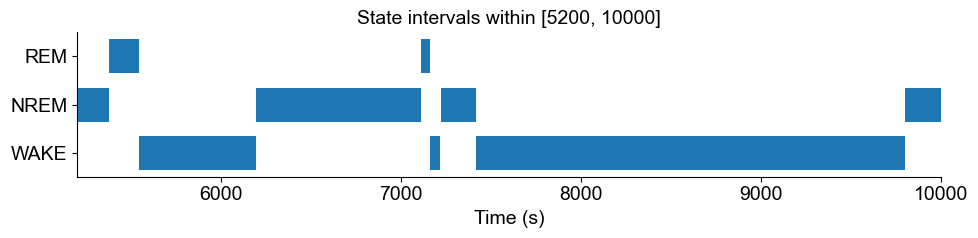

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

start_time = 5200
end_time   = 10000

def _clip_intervals(iv, t0, t1):
    """iv: (N,2) array; returns clipped intervals within [t0,t1]."""
    iv = np.asarray(iv, float)
    if iv.size == 0:
        return np.empty((0,2), float)
    a = np.maximum(iv[:, 0], t0)
    b = np.minimum(iv[:, 1], t1)
    out = np.column_stack([a, b])
    return out[out[:, 1] > out[:, 0]]

# --- 1) clip intervals ---
nrem_iv = _clip_intervals(nrem_epochs.data, start_time, end_time)
rem_iv  = _clip_intervals(rem_epochs.data,  start_time, end_time)
wake_iv = _clip_intervals(awake_epochs.data, start_time, end_time)

# --- 2) make a time-ordered table ---
rows = []
for state, iv in [("WAKE", wake_iv), ("NREM", nrem_iv), ("REM", rem_iv)]:
    for s, e in iv:
        rows.append((s, e, state))

df = pd.DataFrame(rows, columns=["start", "stop", "state"]).sort_values("start").reset_index(drop=True)
df["dur"] = df["stop"] - df["start"]

print(df.head(20))
print("\nCounts:", df["state"].value_counts().to_dict())

# --- 3) plot as rows (one row per state) ---
state_order = ["WAKE", "NREM", "REM"]
ypos = {st:i for i, st in enumerate(state_order)}

fig, ax = plt.subplots(figsize=(10, 2.6))

for st in state_order:
    sub = df[df["state"] == st]
    xranges = [(r.start, r.stop - r.start) for r in sub.itertuples(index=False)]
    if xranges:
        ax.broken_barh(xranges, (ypos[st] - 0.35, 0.7))  # default color cycle

ax.set_xlim(start_time, end_time)
ax.set_yticks([ypos[s] for s in state_order])
ax.set_yticklabels(state_order)
ax.set_xlabel("Time (s)")
ax.set_title(f"State intervals within [{start_time}, {end_time}]")

ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()
